## Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from algorithms import plain_smoothed

In [6]:
from data_utils import generate_1d_trajectory_distribution

In [7]:
# %matplotlib ipympl
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


### Hyperparameters

In [20]:
steps_num = 100
sigma_smoothing = 0.1  # Smoothing parameter
M_noise_samples = 100  # M noise samples

## Data

In [69]:
n_demos = 10
n_steps = 100
T, Y = generate_1d_trajectory_distribution(n_demos, n_steps)
Y = Y.squeeze()

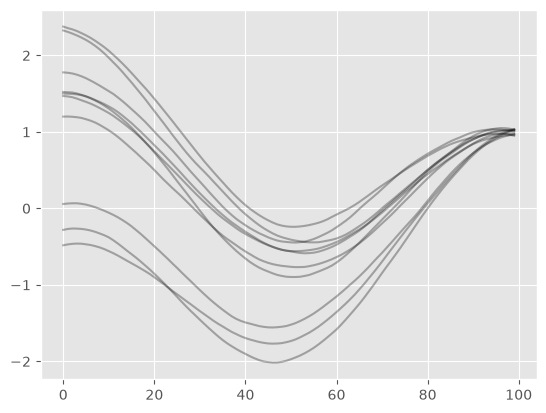

In [70]:
with plt.style.context("ggplot"):
    fig, ax = plt.subplots()
    for demo_i in range(n_demos):
        ax.plot(Y[demo_i, :], color="k", alpha=0.3)
    plt.show()

In [71]:
X = np.hstack([np.tile(T, n_demos)[:, np.newaxis], Y.reshape((n_demos * n_steps, 1))])

## Model

In [72]:
samples_out = n_demos * n_steps  # Number of samples to be generated
samples_out

1000

In [73]:
z_list = plain_smoothed(
    X=X, S=steps_num, K=samples_out, sigma=sigma_smoothing, M=M_noise_samples
)

  0%|          | 0/1000 [00:00<?, ?it/s]

In [74]:
z_list.shape

(1000, 100, 2)

## Visualization

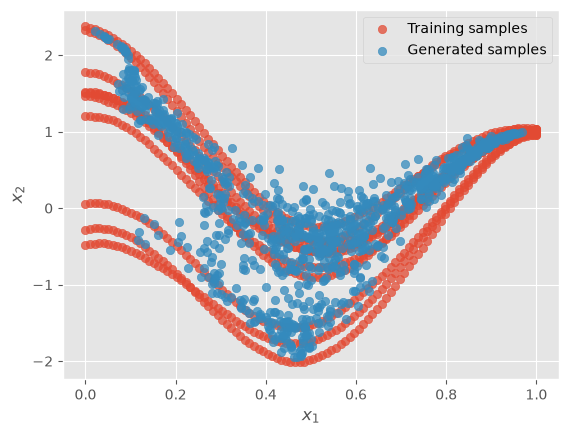

In [75]:
with plt.style.context("ggplot"):
    fig, ax = plt.subplots()
    ax.scatter(X[:, 0], X[:, 1], label="Training samples", alpha=0.75)
    ax.scatter(
        z_list[:, -1, 0], z_list[:, -1, 1], label="Generated samples", alpha=0.75
    )
    ax.legend(loc="best")
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")
    plt.show()

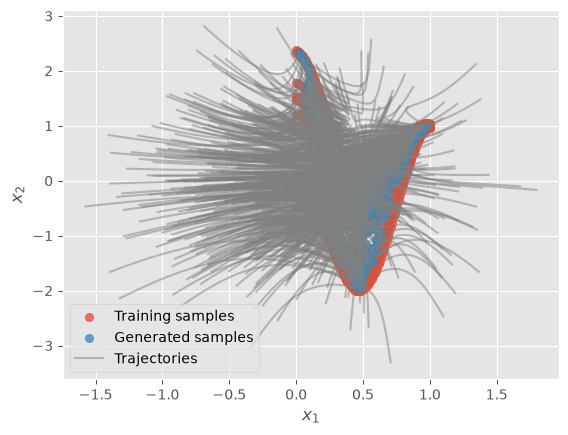

In [76]:
with plt.style.context("ggplot"):
    fig, ax = plt.subplots()
    ax.scatter(X[:, 0], X[:, 1], label="Training samples", alpha=0.75)
    ax.scatter(
        z_list[:, -1, 0], z_list[:, -1, 1], label="Generated samples", alpha=0.75
    )
    for traj_i in range(z_list.shape[0]):
        if traj_i == 0:
            ax.plot(
                z_list[traj_i, :, 0],
                z_list[traj_i, :, 1],
                label="Trajectories",
                alpha=0.5,
                color="gray",
            )
        else:
            ax.plot(z_list[traj_i, :, 0], z_list[traj_i, :, 1], alpha=0.5, color="gray")
    ax.legend(loc="best")
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")
    plt.show()